# Average Effects

Answers challenge questions 1 and 2, following [`analysis_plan.md`](../analysis_plan.md). All 64,000 customers are analyzed in the group they were assigned to.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import norm, ttest_ind
from statsmodels.stats.multitest import multipletests

df = pd.read_csv("../data/hillstrom.csv")

SEED = 42
RESAMPLES = 10_000
COMPARISONS = [
    ("Mens E-Mail", "No E-Mail"),
    ("Womens E-Mail", "No E-Mail"),
    ("Mens E-Mail", "Womens E-Mail"),
]
groups = {name: frame for name, frame in df.groupby("segment")}

df.groupby("segment")[["visit", "conversion", "spend"]].mean().round(4)

,visit,conversion,spend
segment,,,
Mens E-Mail,0.1828,0.0125,1.4226
No E-Mail,0.1062,0.0057,0.6528
Womens E-Mail,0.1514,0.0088,1.0772


## Spend (primary metric)

Main estimate: Welch t-test with a 95% confidence interval. Robustness check: percentile bootstrap with 10,000 resamples within each group, including customers with zero spend. Holm correction across the three comparisons.

In [2]:
rng = np.random.default_rng(SEED)
bootstrap_means = {}
for name, frame in groups.items():
    spend = frame["spend"].to_numpy()
    bootstrap_means[name] = np.array([rng.choice(spend, size=len(spend)).mean() for _ in range(RESAMPLES)])

rows = []
for treated, control in COMPARISONS:
    a, b = groups[treated]["spend"], groups[control]["spend"]
    welch = ttest_ind(a, b, equal_var=False)
    welch_ci = welch.confidence_interval(0.95)
    bootstrap_ci = np.percentile(bootstrap_means[treated] - bootstrap_means[control], [2.5, 97.5])
    rows.append({
        "comparison": f"{treated} vs {control}",
        "difference": a.mean() - b.mean(),
        "welch_low": welch_ci.low,
        "welch_high": welch_ci.high,
        "bootstrap_low": bootstrap_ci[0],
        "bootstrap_high": bootstrap_ci[1],
        "p_value": welch.pvalue,
    })

spend_effects = pd.DataFrame(rows).set_index("comparison")
reject, holm_p, _, _ = multipletests(spend_effects["p_value"], alpha=0.05, method="holm")
spend_effects["holm_p"] = holm_p
spend_effects["significant_after_holm"] = reject
spend_effects["methods_agree"] = (spend_effects["welch_low"] > 0) == (spend_effects["bootstrap_low"] > 0)
spend_effects["methods_agree"] &= (spend_effects["welch_high"] < 0) == (spend_effects["bootstrap_high"] < 0)
spend_effects.round(4)

,difference,welch_low,welch_high,bootstrap_low,bootstrap_high,p_value,holm_p,significant_after_holm,methods_agree
comparison,,,,,,,,,
Mens E-Mail vs No E-Mail,0.7698,0.4851,1.0545,0.4875,1.0589,0.0000,0.0000,True,True
Womens E-Mail vs No E-Mail,0.4244,0.1690,0.6799,0.1738,0.6853,0.0011,0.0023,True,True
Mens E-Mail vs Womens E-Mail,0.3454,0.0326,0.6583,0.0312,0.6665,0.0305,0.0305,True,True


## Visit and conversion (secondary metrics)

Difference in proportions with a 95% normal-approximation confidence interval. Secondary metrics are not corrected for multiple testing.

In [3]:
z = norm.ppf(0.975)
rows = []
for metric in ["visit", "conversion"]:
    for treated, control in COMPARISONS:
        a, b = groups[treated][metric], groups[control][metric]
        difference = a.mean() - b.mean()
        standard_error = np.sqrt(a.var() / len(a) + b.var() / len(b))
        rows.append({
            "metric": metric,
            "comparison": f"{treated} vs {control}",
            "difference": difference,
            "low": difference - z * standard_error,
            "high": difference + z * standard_error,
        })

rate_effects = pd.DataFrame(rows).set_index(["metric", "comparison"])
(rate_effects * 100).round(2).rename(columns=lambda column: f"{column} (pp)")

difference (pp)  low (pp)  high (pp)
metric     comparison                                                        
visit      Mens E-Mail vs No E-Mail                 7.66      7.00       8.32
           Womens E-Mail vs No E-Mail               4.52      3.89       5.16
           Mens E-Mail vs Womens E-Mail             3.14      2.43       3.84
conversion Mens E-Mail vs No E-Mail                 0.68      0.50       0.86
           Womens E-Mail vs No E-Mail               0.31      0.15       0.47
           Mens E-Mail vs Womens E-Mail             0.37      0.17       0.56

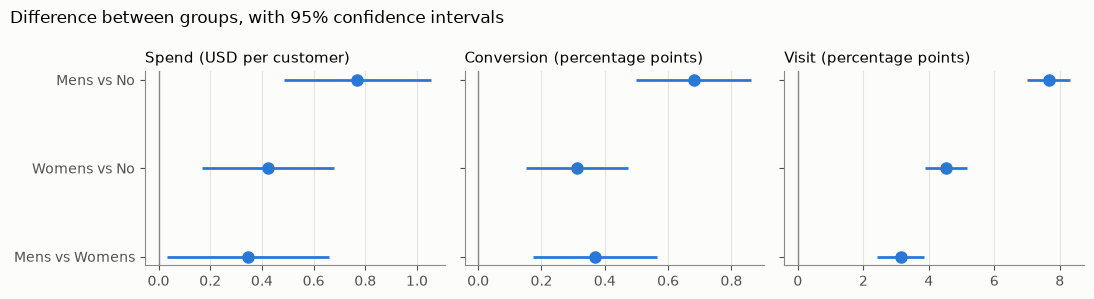

In [4]:
BLUE = "#2a78d6"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#8a8984",
    "axes.titlesize": 11,
    "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "text.parse_math": False,
})

labels = [f"{treated.split()[0]} vs {control.split()[0]}" for treated, control in COMPARISONS]
panels = [
    ("Spend (USD per customer)", spend_effects["difference"], spend_effects["welch_low"], spend_effects["welch_high"]),
    ("Conversion (percentage points)", rate_effects.loc["conversion", "difference"] * 100,
     rate_effects.loc["conversion", "low"] * 100, rate_effects.loc["conversion", "high"] * 100),
    ("Visit (percentage points)", rate_effects.loc["visit", "difference"] * 100,
     rate_effects.loc["visit", "low"] * 100, rate_effects.loc["visit", "high"] * 100),
]

fig, axes = plt.subplots(1, 3, figsize=(11, 3), sharey=True)
positions = np.arange(len(labels))
for ax, (title, estimate, low, high) in zip(axes, panels):
    estimate, low, high = estimate.to_numpy(), low.to_numpy(), high.to_numpy()
    ax.axvline(0, color="#8a8984", linewidth=1)
    ax.hlines(positions, low, high, color=BLUE, linewidth=2)
    ax.plot(estimate, positions, "o", color=BLUE, markersize=8)
    ax.set_title(title)
    ax.grid(axis="x", color="#e4e3df", linewidth=0.8)
    ax.set_axisbelow(True)
axes[0].set_yticks(positions, labels=labels)
axes[0].invert_yaxis()
fig.suptitle("Difference between groups, with 95% confidence intervals", x=0.01, ha="left", fontsize=12)
plt.tight_layout()
fig.savefig("../reports/figures/average_effects.png", dpi=150, bbox_inches="tight")
plt.show()